# 3_1 PyMC with 100 observations

Same as `3_1_pymc.ipynb`, but with the 100-observation 1d Gaussian (`gaussian_1d(100, 3, 1.0, seed=0)`) that the bias heatmaps used before they switched to no observations. The true values are the analytic posterior instead of the prior.

In [1]:
import os
import numpy as np
import pymc as pm
import pytensor

pytensor.config.cxx = '/usr/bin/clang++'

max_iters = int(os.environ.get("SIMPLEVI_PYMC_DEMO_ITERS", "300000"))


In [2]:
mu_prior, sigma_prior = 0, 10
sigma_like = 1.0

from modulars import gaussian_1d, gaussian_1d_posterior
# 100 observations, as the 1d Gaussian in the bias heatmaps used before
# they switched to no observations
data = gaussian_1d(100, 3, sigma_like, seed=0)
true_mu_post, true_sigma_post = gaussian_1d_posterior(data, mu_prior=mu_prior, sigma_prior=sigma_prior, sigma_like=sigma_like)
print(true_mu_post, true_sigma_post)

with pm.Model() as single_model:
    # Define priors
    mu = pm.Normal("mu", mu_prior, sigma_prior)
    likelihood = pm.Normal('y', mu=mu, sigma=sigma_like, observed=data)
    advi = pm.ADVI(random_seed=22)
    single_tracker = pm.callbacks.Tracker(
            mean = advi.approx.mean.eval,
            std = advi.approx.std.eval
        )
    single_fit = advi.fit(
        max_iters, callbacks=[single_tracker])

with pm.Model() as multi_model:
    # Define priors
    mu = pm.Normal("mu", mu_prior, sigma_prior)
    likelihood = pm.Normal('y', mu=mu, sigma=sigma_like, observed=data)
    advi_2 = pm.ADVI(random_seed=10)
    multi_tracker = pm.callbacks.Tracker(
            mean = advi_2.approx.mean.eval,
            std = advi_2.approx.std.eval
        )
    multi_fit = advi_2.fit(
        max_iters, callbacks=[multi_tracker],
        obj_n_mc=100)

3.059502065327952 0.09999500037496875


Output()

Finished [100%]: Average Loss = 147.35


Output()

Finished [100%]: Average Loss = 147.34


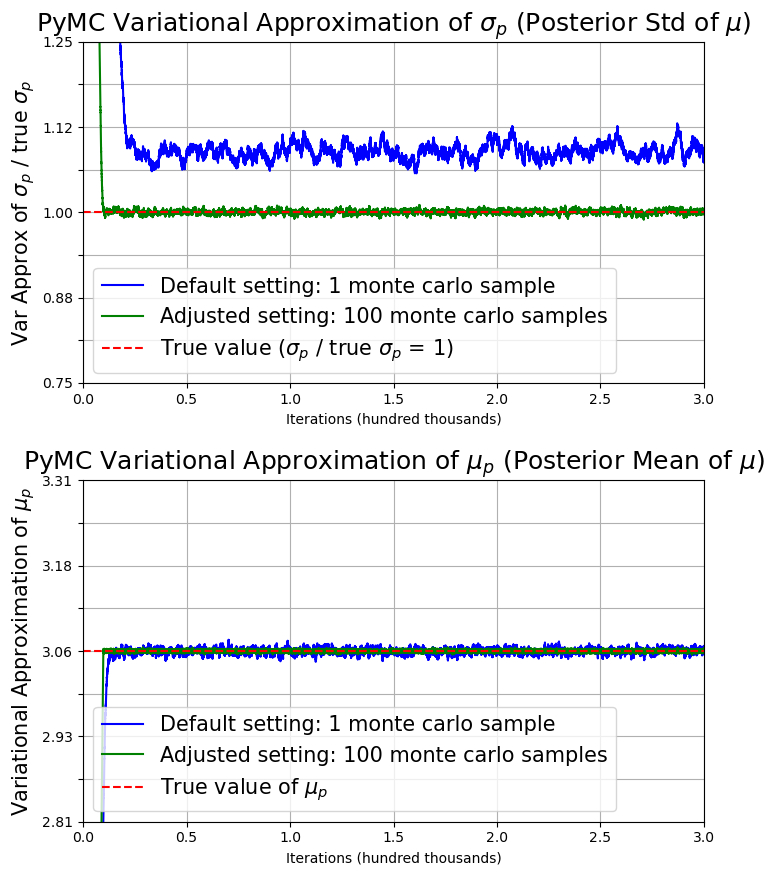

In [3]:
# plot single_tracker vs multi_tracker for the mean and std of mu
# add dashed lines for the true (analytic posterior) mean and std of mu
from modulars.plot_rr import plot_3_1_trajectories
plot_3_1_trajectories(
    single_tracker['mean'],
    np.asarray(single_tracker['std']) / true_sigma_post,
    multi_tracker['mean'],
    np.asarray(multi_tracker['std']) / true_sigma_post,
    framework_name='PyMC',
    max_iters=max_iters,
    true_mu=true_mu_post,
    true_sigma=1.0,
    # the posterior is much narrower than the no-observation prior, so zoom the y axes in
    mean_yticks=true_mu_post + np.linspace(-0.25, 0.25, 9),
    mean_y_labels=[f"{v:.2f}" if i % 2 == 0 else None for i, v in enumerate(true_mu_post + np.linspace(-0.25, 0.25, 9))],
    mean_ylim=(true_mu_post - 0.25, true_mu_post + 0.25),
    # stds divided by the true sigma_p, so the true value is at 1
    std_yticks=1 + np.linspace(-0.25, 0.25, 9),
    std_y_labels=[f"{v:.3f}" if i % 2 == 0 else None for i, v in enumerate(1 + np.linspace(-0.25, 0.25, 9))],
    std_ylim=(0.75, 1.25),
    std_ylabel=r"Var Approx of $\sigma_p$ / true $\sigma_p$",
    std_true_label=r"True value ($\sigma_p$ / true $\sigma_p$ = 1)",
    MILLIONS=False
)


# What about with the adam optimizer?

In [4]:
mu_prior, sigma_prior = 0, 10
sigma_like = 1.0
optimizer = pm.adam()
with pm.Model() as single_model:
    # Define priors
    mu = pm.Normal("mu", mu_prior, sigma_prior)
    likelihood = pm.Normal('y', mu=mu, sigma=sigma_like, observed=data)
    advi = pm.ADVI(random_seed=22)
    single_tracker = pm.callbacks.Tracker(
            mean = advi.approx.mean.eval,
            std = advi.approx.std.eval
        )
    single_fit = advi.fit(
        max_iters, callbacks=[single_tracker],
        obj_optimizer=optimizer,)

with pm.Model() as multi_model:
    # Define priors
    mu = pm.Normal("mu", mu_prior, sigma_prior)
    likelihood = pm.Normal('y', mu=mu, sigma=sigma_like, observed=data)
    advi_2 = pm.ADVI(random_seed=10)
    multi_tracker = pm.callbacks.Tracker(
            mean = advi_2.approx.mean.eval,
            std = advi_2.approx.std.eval
        )
    multi_fit = advi_2.fit(
        max_iters, callbacks=[multi_tracker],
        obj_n_mc=100,
        obj_optimizer=optimizer,)

Output()

Finished [100%]: Average Loss = 147.34


Output()

Finished [100%]: Average Loss = 147.34


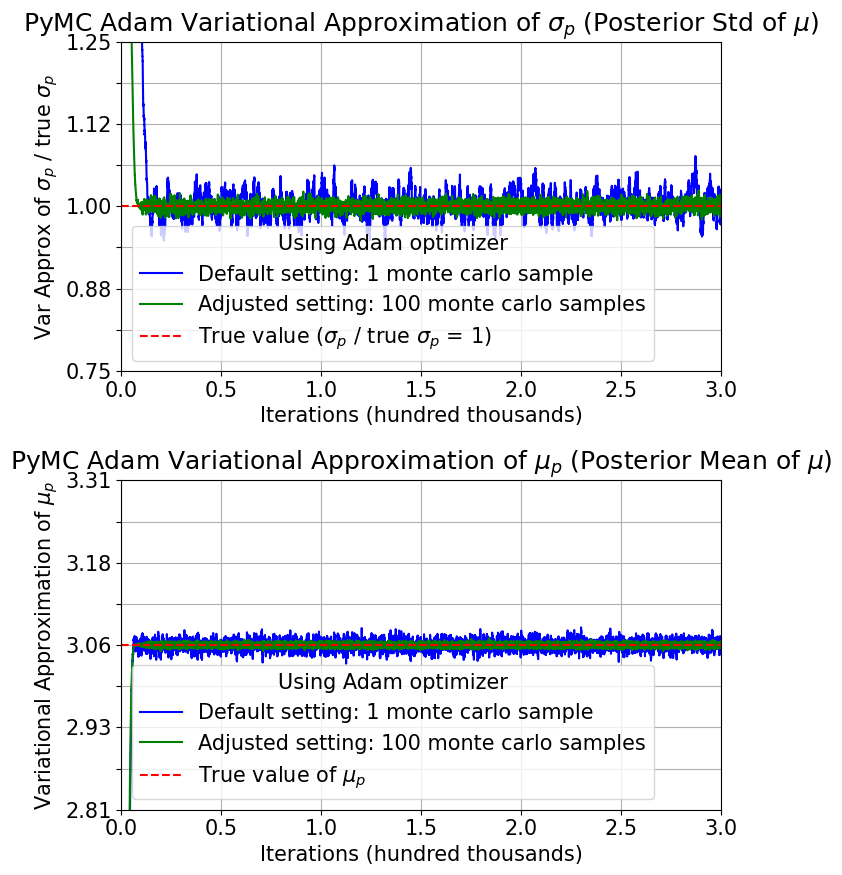

In [5]:

plot_3_1_trajectories(
    single_tracker['mean'],
    np.asarray(single_tracker['std']) / true_sigma_post,
    multi_tracker['mean'],
    np.asarray(multi_tracker['std']) / true_sigma_post,
    framework_name='PyMC',
    max_iters=max_iters,
    true_mu=true_mu_post,
    true_sigma=1.0,
    # the posterior is much narrower than the no-observation prior, so zoom the y axes in
    mean_yticks=true_mu_post + np.linspace(-0.25, 0.25, 9),
    mean_y_labels=[f"{v:.2f}" if i % 2 == 0 else None for i, v in enumerate(true_mu_post + np.linspace(-0.25, 0.25, 9))],
    mean_ylim=(true_mu_post - 0.25, true_mu_post + 0.25),
    # stds divided by the true sigma_p, so the true value is at 1
    std_yticks=1 + np.linspace(-0.25, 0.25, 9),
    std_y_labels=[f"{v:.3f}" if i % 2 == 0 else None for i, v in enumerate(1 + np.linspace(-0.25, 0.25, 9))],
    std_ylim=(0.75, 1.25),
    std_ylabel=r"Var Approx of $\sigma_p$ / true $\sigma_p$",
    std_true_label=r"True value ($\sigma_p$ / true $\sigma_p$ = 1)",
    MILLIONS=False,
    PYMC_ADAM=True
)
